In [22]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [23]:
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


Загрузка данных

In [11]:
DATA_DIR = "./flowers"

In [12]:
classes = os.listdir(DATA_DIR)


In [26]:
paths = []
labels = []

In [27]:
for i, cls in enumerate(classes):
    folder = os.path.join(DATA_DIR, cls)
    
    for file in os.listdir(folder):
        paths.append(os.path.join(folder, file))
        labels.append(i)

In [28]:
paths = np.array(paths)
labels = np.array(labels)

In [29]:
print("Классы:", classes)
print("Всего изображений:", len(paths))

Классы: ['daisy', 'rose', 'tulip', 'dandelion', 'sunflower']
Всего изображений: 4317


### Разбиение на выборки

In [30]:
X_train, X_temp, y_train, y_temp = train_test_split(
    paths, labels, test_size=0.3, random_state=42, stratify=labels
)

In [31]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

In [32]:
len(X_train)

3021

In [33]:
len(X_val)

648

In [34]:
len(X_test)

648

### Загрузка изображений

In [35]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

In [36]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = img / 255.0
    return img, label

In [37]:
def make_dataset(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(1000)
    ds = ds.map(load_image).batch(BATCH_SIZE)
    return ds

In [38]:
train_ds = make_dataset(X_train, y_train, shuffle=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

### Визуализация данных

In [19]:
plt.figure(figsize=(10,5))


<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

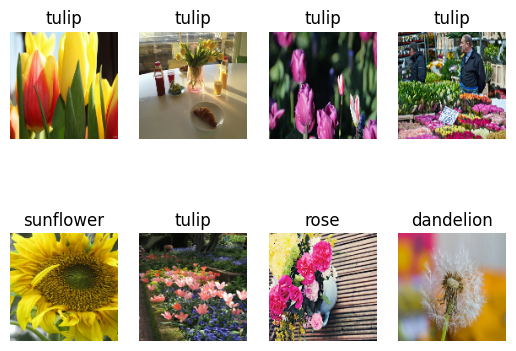

In [20]:
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2,4,i+1)
        plt.imshow(images[i])
        plt.title(classes[int(labels[i])])
        plt.axis("off")

plt.show()

### Аугментация

In [21]:
data_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

### Персептрон (MLP)

In [22]:
mlp = models.Sequential([
    layers.Flatten(input_shape=(128,128,3)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(5, activation="softmax")
])

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [23]:
mlp.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [24]:
history_mlp = mlp.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.2608 - loss: 4.4444 - val_accuracy: 0.3503 - val_loss: 1.4716
Epoch 2/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.3343 - loss: 1.4740 - val_accuracy: 0.3812 - val_loss: 1.3513
Epoch 3/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.3621 - loss: 1.4497 - val_accuracy: 0.3596 - val_loss: 1.4061
Epoch 4/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.3509 - loss: 1.4177 - val_accuracy: 0.3873 - val_loss: 1.3648
Epoch 5/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.3466 - loss: 1.4170 - val_accuracy: 0.3565 - val_loss: 1.4044
Epoch 6/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.3664 - loss: 1.3921 - val_accuracy: 0.3997 - val_loss: 1.3357
Epoch 7/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.3661 - loss: 1.4002 - val_accuracy: 0.4090 - val_loss: 1.3434
Epoch 8/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.3688 - loss: 1.3962 - val_accuracy: 0.3673 - v

### CNN

In [25]:
cnn = models.Sequential([
    data_aug,
    
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(5, activation="softmax")
])

In [26]:
cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
history_cnn = cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 124ms/step - accuracy: 0.4297 - loss: 1.3152 - val_accuracy: 0.5046 - val_loss: 1.1369
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 12s 128ms/step - accuracy: 0.5631 - loss: 1.0808 - val_accuracy: 0.5941 - val_loss: 0.9649
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 132ms/step - accuracy: 0.6094 - loss: 0.9854 - val_accuracy: 0.6096 - val_loss: 1.0424
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 12s 130ms/step - accuracy: 0.6402 - loss: 0.9579 - val_accuracy: 0.6281 - val_loss: 0.9757
Epoch 5/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 132ms/step - accuracy: 0.6723 - loss: 0.8779 - val_accuracy: 0.6806 - val_loss: 0.8240
Epoch 6/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 132ms/step - accuracy: 0.6792 - loss: 0.8311 - val_accuracy: 0.6744 - val_loss: 0.8730
Epoch 7/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 14s 143ms/step - accuracy: 0.6991 - loss: 0.8096 - val_accuracy: 0.6914 - val_loss: 0.8701
Epoch 8/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step - accuracy: 0.7044 - loss: 0.7801 - val_accu

### Предобученная модель

In [28]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128,128,3),
    include_top=False,
    weights="imagenet"
)

In [29]:
base_model.trainable = False


In [30]:
model_pretrained = models.Sequential([
    data_aug,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(5, activation="softmax")
])

In [31]:
model_pretrained.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [32]:
history_pretrained = model_pretrained.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - accuracy: 0.7524 - loss: 0.6719 - val_accuracy: 0.8164 - val_loss: 0.5761
Epoch 2/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.8491 - loss: 0.4010 - val_accuracy: 0.8333 - val_loss: 0.4928
Epoch 3/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.8792 - loss: 0.3305 - val_accuracy: 0.8426 - val_loss: 0.4813
Epoch 4/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step - accuracy: 0.9053 - loss: 0.2685 - val_accuracy: 0.8086 - val_loss: 0.6210
Epoch 5/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step - accuracy: 0.9033 - loss: 0.2562 - val_accuracy: 0.8410 - val_loss: 0.5142
Epoch 6/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - accuracy: 0.9186 - loss: 0.2179 - val_accuracy: 0.8333 - val_loss: 0.5686
Epoch 7/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.9341 - loss: 0.1851 - val_accuracy: 0.8472 - val_loss: 0.5489
Epoch 8/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.9398 - loss: 0.1664 - val_accuracy: 0.8133 - v

### Графики обучения

In [33]:
def plot_history(history, title):
    plt.figure(figsize=(10,4))
    
    plt.subplot(1,2,1)
    plt.plot(history.history["accuracy"], label="train")
    plt.plot(history.history["val_accuracy"], label="val")
    plt.title(title + " accuracy")
    plt.legend()
    
    plt.subplot(1,2,2)
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="val")
    plt.title(title + " loss")
    plt.legend()
    
    plt.show()

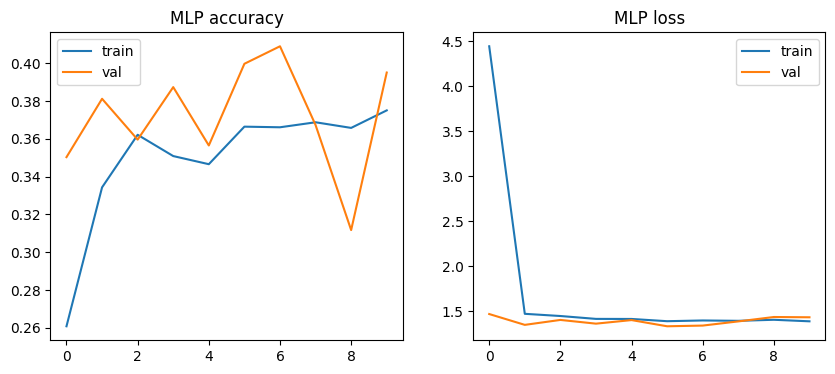

In [34]:
plot_history(history_mlp, "MLP")

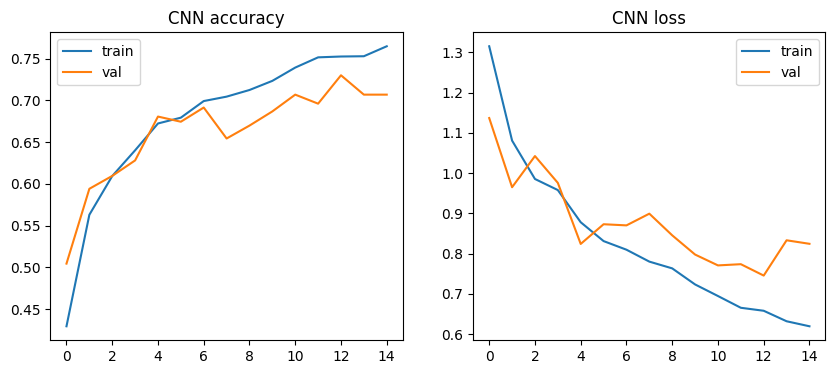

In [35]:
plot_history(history_cnn, "CNN")

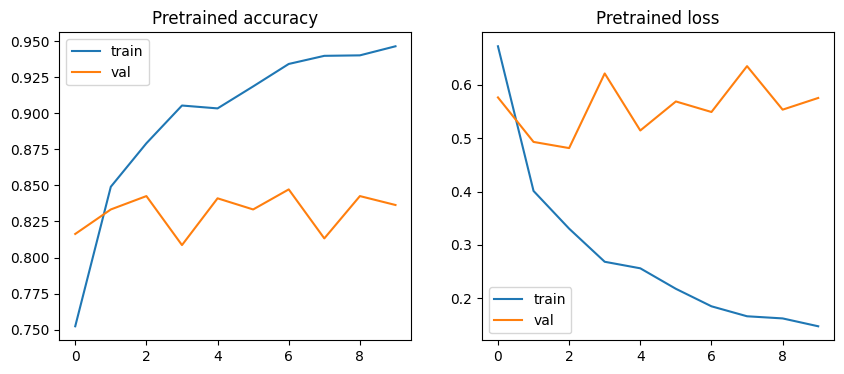

In [36]:
plot_history(history_pretrained, "Pretrained")

### Оценка моделей

In [37]:
def evaluate(model, name):
    y_pred = np.argmax(model.predict(test_ds), axis=1)
    
    print("====", name, "====")
    print(classification_report(y_test, y_pred, target_names=classes))
    
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=classes).plot()
    plt.show()
    
    return y_pred

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
==== MLP ====
              precision    recall  f1-score   support

       daisy       0.35      0.45      0.40       115
        rose       0.62      0.09      0.15       117
       tulip       0.32      0.67      0.43       148
   dandelion       0.40      0.32      0.36       158
   sunflower       0.64      0.25      0.36       110

    accuracy                           0.37       648
   macro avg       0.47      0.35      0.34       648
weighted avg       0.45      0.37      0.34       648



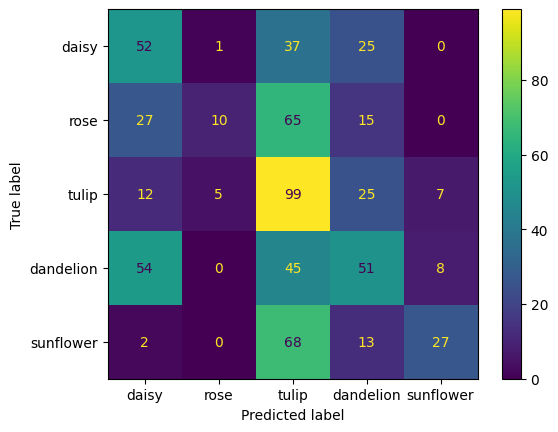

In [38]:
pred_mlp = evaluate(mlp, "MLP")

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
==== CNN ====
              precision    recall  f1-score   support

       daisy       0.70      0.75      0.73       115
        rose       0.56      0.72      0.63       117
       tulip       0.79      0.59      0.68       148
   dandelion       0.88      0.58      0.70       158
   sunflower       0.61      0.90      0.73       110

    accuracy                           0.69       648
   macro avg       0.71      0.71      0.69       648
weighted avg       0.73      0.69      0.69       648



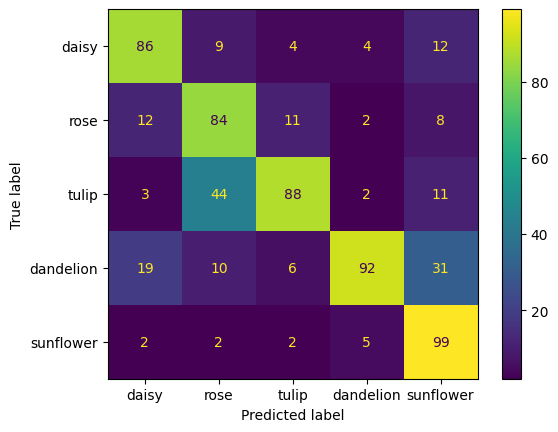

In [39]:
pred_cnn = evaluate(cnn, "CNN")

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step
==== Pretrained ====
              precision    recall  f1-score   support

       daisy       0.91      0.75      0.82       115
        rose       0.91      0.83      0.87       117
       tulip       0.83      0.92      0.87       148
   dandelion       0.93      0.88      0.90       158
   sunflower       0.74      0.90      0.81       110

    accuracy                           0.86       648
   macro avg       0.86      0.86      0.86       648
weighted avg       0.87      0.86      0.86       648



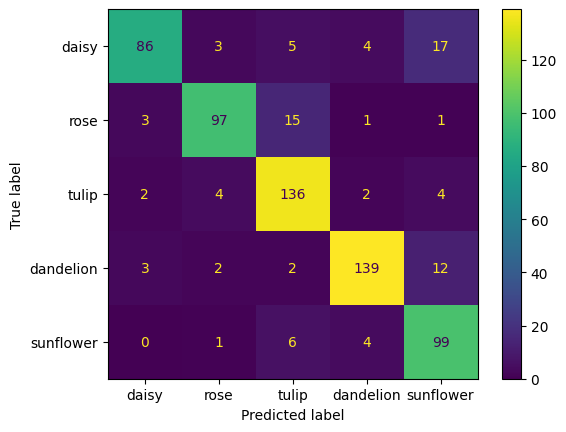

In [40]:
pred_pre = evaluate(model_pretrained, "Pretrained")

### Ошибки модели

In [27]:
def show_errors(preds, model_name):
    wrong = np.where(preds != y_test)[0]
    
    print(model_name, "ошибок:", len(wrong))
    
    plt.figure(figsize=(10,6))
    
    for i, idx in enumerate(wrong[:8]):
        img = tf.io.read_file(X_test[idx])
        img = tf.image.decode_jpeg(img)
        
        plt.subplot(2,4,i+1)
        plt.imshow(img)
        plt.title(f"true: {classes[y_test[idx]]}\npred: {classes[preds[idx]]}")
        plt.axis("off")
    
    plt.show()

MLP ошибок: 409


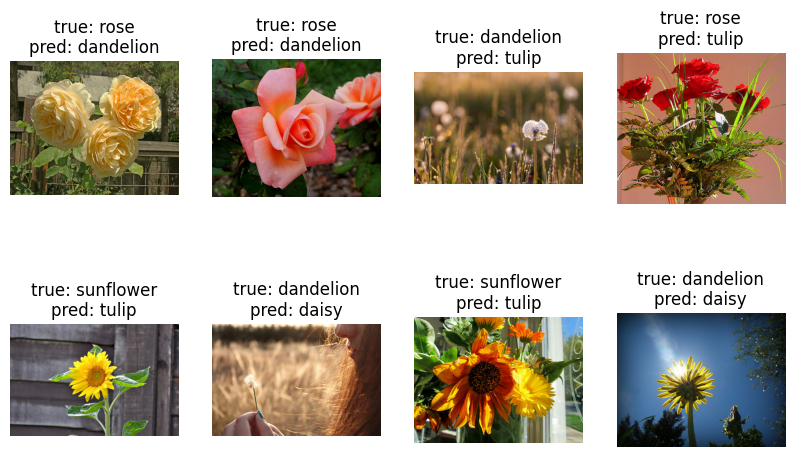

In [42]:
show_errors(pred_mlp, "MLP")


CNN ошибок: 199


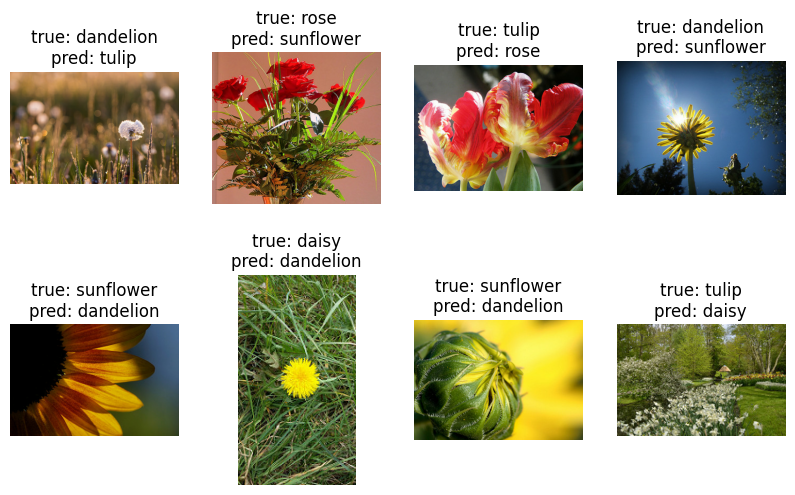

In [43]:
show_errors(pred_cnn, "CNN")

Pretrained ошибок: 91


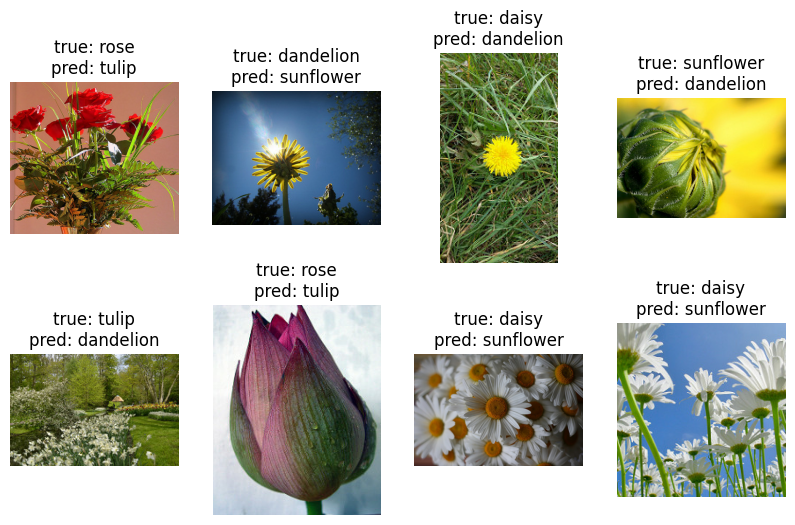

In [44]:
show_errors(pred_pre, "Pretrained")

## 3.6 

### Сохраняем и загружаем модель

In [46]:
mlp.save("mlp_flowers.keras")
cnn.save("cnn_flowers.keras")
model_pretrained.save("pretrained_flowers.keras")

In [30]:
mlp = tf.keras.models.load_model("mlp_flowers.keras", compile=False)

In [31]:
cnn = tf.keras.models.load_model("cnn_flowers.keras", compile=False)

In [32]:
model_pretrained = tf.keras.models.load_model("pretrained_flowers.keras", compile=False)

### Проверка на своих данных

In [33]:
from pathlib import Path
import pandas as pd

In [34]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

In [35]:
def collect_images(root_dir, class_names):
    rows = []
    root_dir = Path(root_dir)
    
    for cls in class_names:
        class_folder = root_dir / cls
        if not class_folder.exists():
            continue
        
        for file in class_folder.iterdir():
            if file.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]:
                rows.append([str(file), cls])
    
    return pd.DataFrame(rows, columns=["filepath", "class_name"])

In [36]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

In [37]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = img / 255.0
    return img, label

In [52]:
def make_tf_dataset(df):
    paths = df["filepath"].values
    labels = df["label"].values
    
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

### Оценка модели на новой папке

In [39]:
def evaluate_on_folder(model, root_dir, class_names, title):
    df = collect_images(root_dir, class_names)
    df["label"] = df["class_name"].map({cls: i for i, cls in enumerate(class_names)})
    
    print(f"\n{title}")
    print("Всего изображений:", len(df))
    print(df["class_name"].value_counts())
    
    ds = make_tf_dataset(df)
    y_true = df["label"].values
    y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))
    
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
    plt.title(title)
    plt.xticks(rotation=20)
    plt.show()
    
    acc = np.mean(y_true == y_pred)
    print("Accuracy:", round(acc, 4))
    
    return df, y_true, y_pred

In [40]:
MY_DATA_DIR = "my_data" 


MLP на своих данных
Всего изображений: 79
class_name
dandelion    18
daisy        16
tulip        16
sunflower    15
rose         14
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

       daisy     0.6154    0.5000    0.5517        16
        rose     1.0000    0.1429    0.2500        14
       tulip     0.3333    0.8750    0.4828        16
   dandelion     0.5385    0.3889    0.4516        18
   sunflower     0.6667    0.4000    0.5000        15

    accuracy                         0.4684        79
   macro avg     0.6308    0.4613    0.4472        79
weighted avg     0.6186    0.4684    0.4517        79



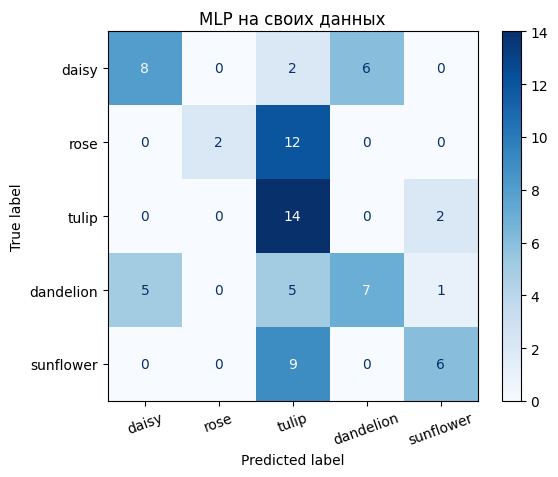

Accuracy: 0.4684


In [41]:
df_mlp, y_true_mlp, y_pred_mlp = evaluate_on_folder(
    mlp,
    MY_DATA_DIR,
    classes,
    "MLP на своих данных"
)


CNN на своих данных
Всего изображений: 79
class_name
dandelion    18
daisy        16
tulip        16
sunflower    15
rose         14
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

       daisy     0.8421    1.0000    0.9143        16
        rose     0.7222    0.9286    0.8125        14
       tulip     0.7857    0.6875    0.7333        16
   dandelion     1.0000    0.1667    0.2857        18
   sunflower     0.6000    1.0000    0.7500        15

    accuracy                         0.7342        79
   macro avg     0.7900    0.7565    0.6992        79
weighted avg     0.7994    0.7342    0.6852        79



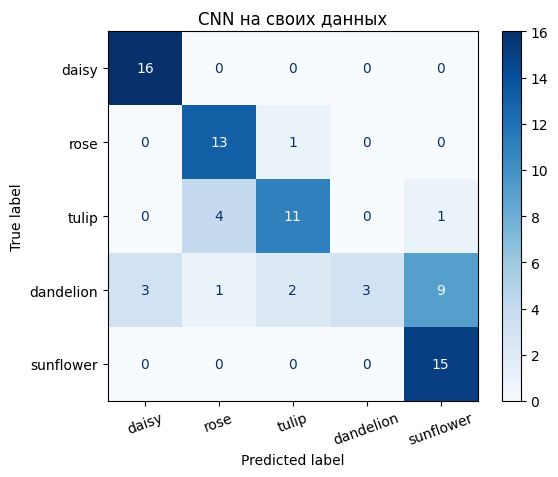

Accuracy: 0.7342


In [35]:
df_cnn, y_true_cnn, y_pred_cnn = evaluate_on_folder(
    cnn,
    MY_DATA_DIR,
    classes,
    "CNN на своих данных"
)


Pretrained на своих данных
Всего изображений: 79
class_name
dandelion    18
daisy        16
tulip        16
sunflower    15
rose         14
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

       daisy     0.9231    0.7500    0.8276        16
        rose     1.0000    0.8571    0.9231        14
       tulip     0.8235    0.8750    0.8485        16
   dandelion     1.0000    0.5556    0.7143        18
   sunflower     0.5556    1.0000    0.7143        15

    accuracy                         0.7975        79
   macro avg     0.8604    0.8075    0.8055        79
weighted avg     0.8643    0.7975    0.8014        79



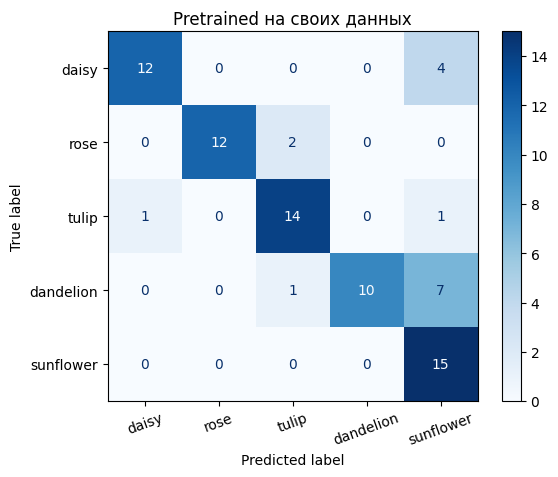

Accuracy: 0.7975


In [36]:
df_pre, y_true_pre, y_pred_pre = evaluate_on_folder(
    model_pretrained,
    MY_DATA_DIR,
    classes,
    "Pretrained на своих данных"
)

### Проверка на ручной аугментации

In [37]:
import os


In [38]:
manual_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
])

  Берёт несколько изображений из каждого класса и сохраняет аугментированные копии.

In [39]:
def save_manual_augmented_images(source_df, out_dir, per_class=10):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    
    for cls in source_df["class_name"].unique():
        class_df = source_df[source_df["class_name"] == cls].sample(
            n=min(per_class, len(source_df[source_df["class_name"] == cls])),
            random_state=42
        )
        
        class_out = out_dir / cls
        class_out.mkdir(exist_ok=True)
        
        for i, (_, row) in enumerate(class_df.iterrows()):
            img = tf.io.read_file(row["filepath"])
            img = tf.image.decode_jpeg(img, channels=3)
            img = tf.image.resize(img, IMG_SIZE)
            img = tf.cast(img, tf.float32) / 255.0
            
            # применяем аугментацию как слой
            aug_img = manual_aug(tf.expand_dims(img, 0))[0]
            
            tf.keras.utils.save_img(str(class_out / f"aug_{i}.jpg"), aug_img)
    
    print("Аугментированные данные в:", out_dir)

In [40]:
source_df = collect_images("my_data", classes)

In [41]:
save_manual_augmented_images(source_df, "manual_augmented", per_class=10)

Аугментированные данные в: manual_augmented



MLP на ручной аугментации
Всего изображений: 50
class_name
daisy        10
rose         10
tulip        10
dandelion    10
sunflower    10
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

       daisy     0.5000    0.2000    0.2857        10
        rose     0.0000    0.0000    0.0000        10
       tulip     0.3030    1.0000    0.4651        10
   dandelion     0.2222    0.2000    0.2105        10
   sunflower     1.0000    0.4000    0.5714        10

    accuracy                         0.3600        50
   macro avg     0.4051    0.3600    0.3066        50
weighted avg     0.4051    0.3600    0.3066        50



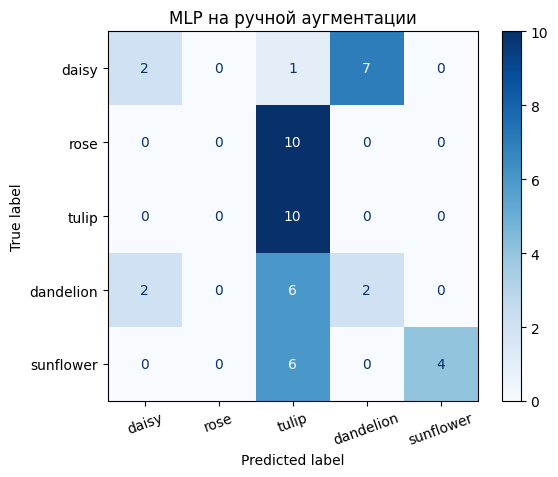

Accuracy: 0.36


(                                filepath class_name  label
 0       manual_augmented/daisy/aug_6.jpg      daisy      0
 1       manual_augmented/daisy/aug_7.jpg      daisy      0
 2       manual_augmented/daisy/aug_5.jpg      daisy      0
 3       manual_augmented/daisy/aug_4.jpg      daisy      0
 4       manual_augmented/daisy/aug_0.jpg      daisy      0
 5       manual_augmented/daisy/aug_1.jpg      daisy      0
 6       manual_augmented/daisy/aug_3.jpg      daisy      0
 7       manual_augmented/daisy/aug_2.jpg      daisy      0
 8       manual_augmented/daisy/aug_9.jpg      daisy      0
 9       manual_augmented/daisy/aug_8.jpg      daisy      0
 10       manual_augmented/rose/aug_6.jpg       rose      1
 11       manual_augmented/rose/aug_7.jpg       rose      1
 12       manual_augmented/rose/aug_5.jpg       rose      1
 13       manual_augmented/rose/aug_4.jpg       rose      1
 14       manual_augmented/rose/aug_0.jpg       rose      1
 15       manual_augmented/rose/aug_1.jp

In [42]:
evaluate_on_folder(
    mlp,
    "manual_augmented",
    classes,
    "MLP на ручной аугментации"
)



CNN на ручной аугментации
Всего изображений: 50
class_name
daisy        10
rose         10
tulip        10
dandelion    10
sunflower    10
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

       daisy     0.8889    0.8000    0.8421        10
        rose     0.6000    0.9000    0.7200        10
       tulip     0.7500    0.6000    0.6667        10
   dandelion     0.6667    0.2000    0.3077        10
   sunflower     0.6667    1.0000    0.8000        10

    accuracy                         0.7000        50
   macro avg     0.7144    0.7000    0.6673        50
weighted avg     0.7144    0.7000    0.6673        50



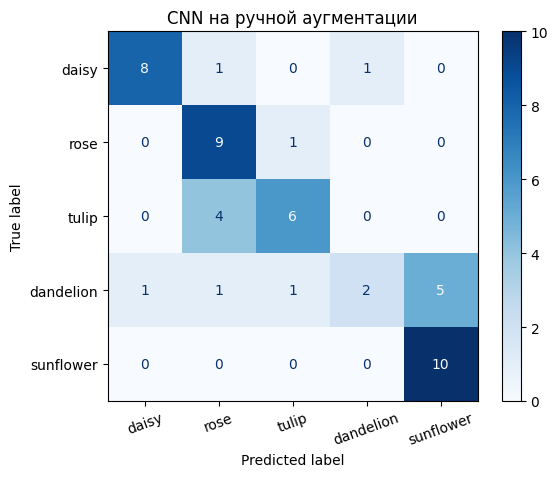

Accuracy: 0.7


(                                filepath class_name  label
 0       manual_augmented/daisy/aug_6.jpg      daisy      0
 1       manual_augmented/daisy/aug_7.jpg      daisy      0
 2       manual_augmented/daisy/aug_5.jpg      daisy      0
 3       manual_augmented/daisy/aug_4.jpg      daisy      0
 4       manual_augmented/daisy/aug_0.jpg      daisy      0
 5       manual_augmented/daisy/aug_1.jpg      daisy      0
 6       manual_augmented/daisy/aug_3.jpg      daisy      0
 7       manual_augmented/daisy/aug_2.jpg      daisy      0
 8       manual_augmented/daisy/aug_9.jpg      daisy      0
 9       manual_augmented/daisy/aug_8.jpg      daisy      0
 10       manual_augmented/rose/aug_6.jpg       rose      1
 11       manual_augmented/rose/aug_7.jpg       rose      1
 12       manual_augmented/rose/aug_5.jpg       rose      1
 13       manual_augmented/rose/aug_4.jpg       rose      1
 14       manual_augmented/rose/aug_0.jpg       rose      1
 15       manual_augmented/rose/aug_1.jp

In [43]:
evaluate_on_folder(
    cnn,
    "manual_augmented",
    classes,
    "CNN на ручной аугментации"
)


 на ручной аугментации
Всего изображений: 50
class_name
daisy        10
rose         10
tulip        10
dandelion    10
sunflower    10
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

       daisy     1.0000    0.8000    0.8889        10
        rose     0.8000    0.8000    0.8000        10
       tulip     0.7500    0.9000    0.8182        10
   dandelion     0.6667    0.6000    0.6316        10
   sunflower     0.8182    0.9000    0.8571        10

    accuracy                         0.8000        50
   macro avg     0.8070    0.8000    0.7992        50
weighted avg     0.8070    0.8000    0.7992        50



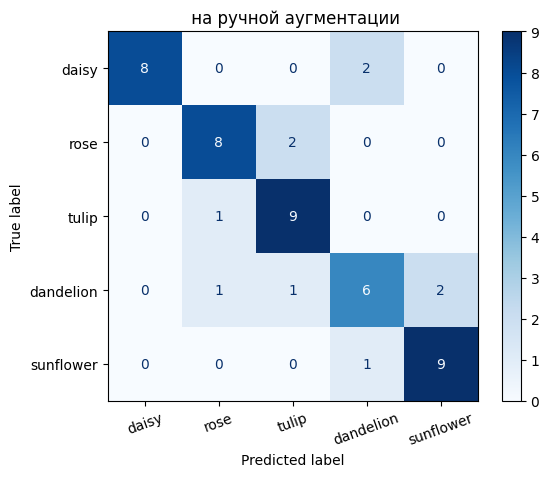

Accuracy: 0.8


(                                filepath class_name  label
 0       manual_augmented/daisy/aug_6.jpg      daisy      0
 1       manual_augmented/daisy/aug_7.jpg      daisy      0
 2       manual_augmented/daisy/aug_5.jpg      daisy      0
 3       manual_augmented/daisy/aug_4.jpg      daisy      0
 4       manual_augmented/daisy/aug_0.jpg      daisy      0
 5       manual_augmented/daisy/aug_1.jpg      daisy      0
 6       manual_augmented/daisy/aug_3.jpg      daisy      0
 7       manual_augmented/daisy/aug_2.jpg      daisy      0
 8       manual_augmented/daisy/aug_9.jpg      daisy      0
 9       manual_augmented/daisy/aug_8.jpg      daisy      0
 10       manual_augmented/rose/aug_6.jpg       rose      1
 11       manual_augmented/rose/aug_7.jpg       rose      1
 12       manual_augmented/rose/aug_5.jpg       rose      1
 13       manual_augmented/rose/aug_4.jpg       rose      1
 14       manual_augmented/rose/aug_0.jpg       rose      1
 15       manual_augmented/rose/aug_1.jp

In [44]:
evaluate_on_folder(
    model_pretrained,
    "manual_augmented",
    classes,
    " на ручной аугментации")

###  с помощью генеративного ИИ 

In [48]:
import torch
from diffusers import StableDiffusionPipeline
import os
from tqdm import tqdm
import matplotlib.pyplot as plt

In [47]:
AI_DATA_DIR = "./ai_generated"
os.makedirs(AI_DATA_DIR, exist_ok=True)
for cls in classes:
    os.makedirs(os.path.join(AI_DATA_DIR, cls), exist_ok=True)

загрузка модели

In [12]:
pipe = StableDiffusionPipeline.from_pretrained(
    "CompVis/stable-diffusion-v1-4",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    safety_checker=None,
    requires_safety_checker=False
)

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [13]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
pipe = pipe.to(device)
pipe.safety_checker = None

In [14]:
print(f"Генерация на устройстве: {device}")

Генерация на устройстве: mps


Параметры генерации:

In [15]:
num_images_per_class = 10      # можно увеличить до 20-30
guidance_scale = 7.5
num_inference_steps = 30
seed = 42

In [16]:
generator = torch.Generator(device=device).manual_seed(seed)

In [17]:
prompt_templates = {
    "daisy": "high quality photo of a beautiful daisy flower, white petals with yellow center, detailed, natural lighting, realistic, 8k",
    "rose": "high quality photo of a red rose flower, detailed petals, dew drops, natural sunlight, realistic, 8k",
    "tulip": "high quality photo of a pink tulip flower, detailed, garden setting, realistic, sharp focus",
    "dandelion": "high quality photo of a bright yellow dandelion flower, detailed, meadow, realistic",
    "sunflower": "high quality photo of a large yellow sunflower, detailed petals and seeds, sunny day, realistic"
}

цикл генерации

Генерация daisy:   0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

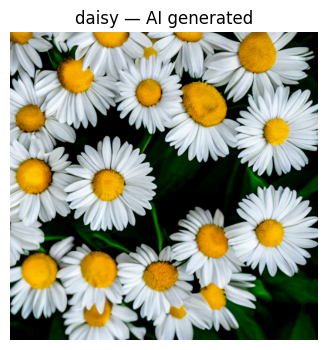

Генерация daisy:  10%|█         | 1/10 [00:49<07:22, 49.12s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

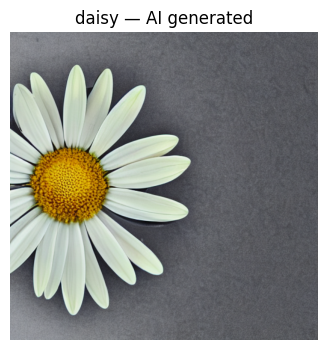

Генерация daisy:  20%|██        | 2/10 [01:33<06:08, 46.08s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация daisy:  30%|███       | 3/10 [02:17<05:17, 45.36s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация daisy:  40%|████      | 4/10 [03:08<04:46, 47.72s/it]

...

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация daisy:  90%|█████████ | 9/10 [07:55<00:55, 55.81s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация rose:   0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

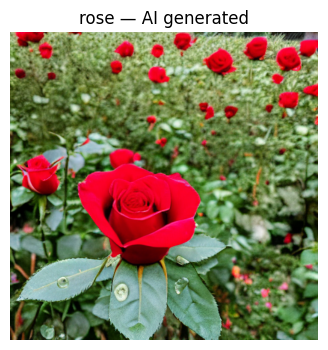

Генерация rose:  10%|█         | 1/10 [00:57<08:35, 57.24s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

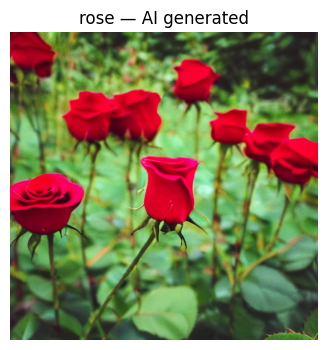

Генерация rose:  20%|██        | 2/10 [01:56<07:45, 58.21s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация rose:  30%|███       | 3/10 [02:58<06:59, 59.91s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация rose:  40%|████      | 4/10 [03:58<06:00, 60.06s/it]

...

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация rose:  90%|█████████ | 9/10 [09:12<01:02, 62.30s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация tulip:   0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

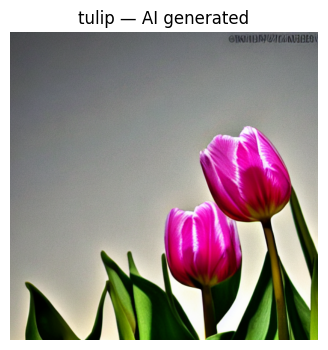

Генерация tulip:  10%|█         | 1/10 [01:01<09:10, 61.13s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

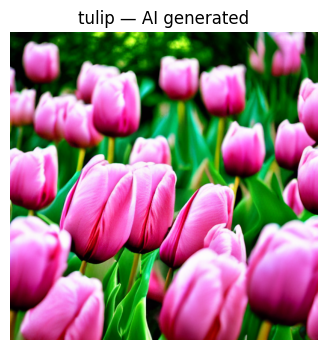

Генерация tulip:  20%|██        | 2/10 [02:08<08:38, 64.80s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация tulip:  30%|███       | 3/10 [03:10<07:24, 63.57s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация tulip:  40%|████      | 4/10 [04:13<06:18, 63.14s/it]

...

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация tulip:  90%|█████████ | 9/10 [09:48<01:06, 66.90s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация dandelion:   0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

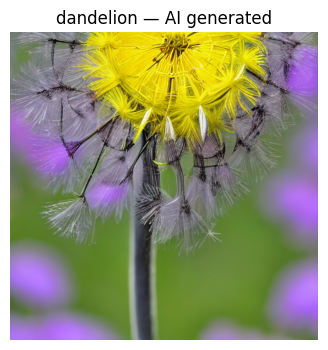

Генерация dandelion:  10%|█         | 1/10 [01:07<10:09, 67.74s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

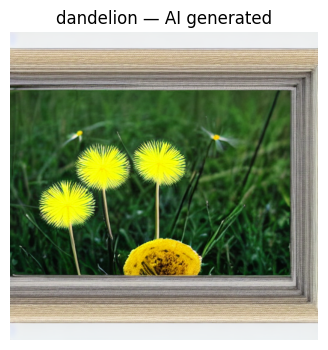

Генерация dandelion:  20%|██        | 2/10 [02:13<08:53, 66.73s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация dandelion:  30%|███       | 3/10 [03:16<07:34, 64.86s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация dandelion:  40%|████      | 4/10 [04:19<06:25, 64.23s/it]

...

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация dandelion:  90%|█████████ | 9/10 [09:39<01:03, 63.94s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация sunflower:   0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

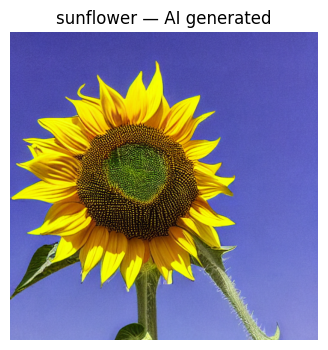

Генерация sunflower:  10%|█         | 1/10 [01:03<09:28, 63.15s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

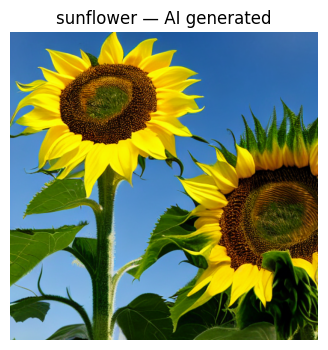

Генерация sunflower:  20%|██        | 2/10 [02:06<08:24, 63.12s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация sunflower:  30%|███       | 3/10 [03:07<07:17, 62.45s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация sunflower:  40%|████      | 4/10 [04:09<06:13, 62.24s/it]

...

Генерация sunflower:  80%|████████  | 8/10 [08:33<02:11, 65.78s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация sunflower:  90%|█████████ | 9/10 [09:51<01:09, 69.47s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

Генерация sunflower: 100%|██████████| 10/10 [10:58<00:00, 65.89s/it]


In [18]:
for cls in classes:
    prompt_base = prompt_templates.get(cls, f"high quality photo of a {cls} flower, detailed, realistic")
    
    for j in tqdm(range(num_images_per_class), desc=f"Генерация {cls}"):
        prompt = prompt_base + f", variation {j}, different angle"
        
        image = pipe(
            prompt,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            generator=generator
        ).images[0]
        
        save_path = os.path.join(AI_DATA_DIR, cls, f"ai_{cls}_{j:03d}.jpg")
        image.save(save_path)
        
        # Показываем первые изображения для контроля
        if j < 2:
            plt.figure(figsize=(4,4))
            plt.imshow(image)
            plt.title(f"{cls} — AI generated")
            plt.axis('off')
            plt.show()

In [45]:
ai_df = collect_images(AI_DATA_DIR, classes)  # твоя функция из ноутбука
print(f"Сгенерировано AI изображений: {len(ai_df)}")

Сгенерировано AI изображений: 50



 на AI-генерации
Всего изображений: 50
class_name
daisy        10
rose         10
tulip        10
dandelion    10
sunflower    10
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

       daisy     1.0000    1.0000    1.0000        10
        rose     1.0000    0.7000    0.8235        10
       tulip     0.7143    1.0000    0.8333        10
   dandelion     1.0000    0.7000    0.8235        10
   sunflower     0.8333    1.0000    0.9091        10

    accuracy                         0.8800        50
   macro avg     0.9095    0.8800    0.8779        50
weighted avg     0.9095    0.8800    0.8779        50



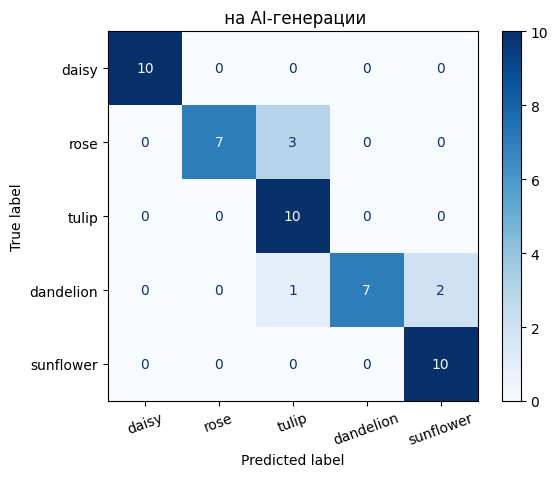

Accuracy: 0.88

 на AI-генерации
Всего изображений: 50
class_name
daisy        10
rose         10
tulip        10
dandelion    10
sunflower    10
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

       daisy     1.0000    1.0000    1.0000        10
        rose     1.0000    0.7000    0.8235        10
       tulip     0.6667    1.0000    0.8000        10
   dandelion     1.0000    0.2000    0.3333        10
   sunflower     0.6250    1.0000    0.7692        10

    accuracy                         0.7800        50
   macro avg     0.8583    0.7800    0.7452        50
weighted avg     0.8583    0.7800    0.7452        50



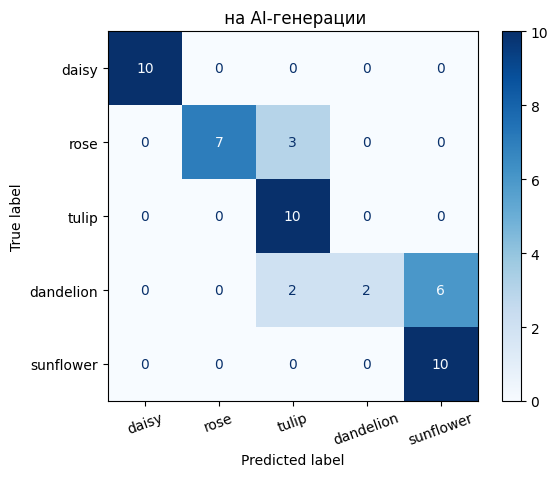

Accuracy: 0.78


(                                       filepath class_name  label
 0           ai_generated/daisy/ai_daisy_009.jpg      daisy      0
 1           ai_generated/daisy/ai_daisy_008.jpg      daisy      0
 2           ai_generated/daisy/ai_daisy_003.jpg      daisy      0
 3           ai_generated/daisy/ai_daisy_002.jpg      daisy      0
 4           ai_generated/daisy/ai_daisy_000.jpg      daisy      0
 5           ai_generated/daisy/ai_daisy_001.jpg      daisy      0
 6           ai_generated/daisy/ai_daisy_005.jpg      daisy      0
 7           ai_generated/daisy/ai_daisy_004.jpg      daisy      0
 8           ai_generated/daisy/ai_daisy_006.jpg      daisy      0
 9           ai_generated/daisy/ai_daisy_007.jpg      daisy      0
 10            ai_generated/rose/ai_rose_003.jpg       rose      1
 11            ai_generated/rose/ai_rose_002.jpg       rose      1
 12            ai_generated/rose/ai_rose_000.jpg       rose      1
 13            ai_generated/rose/ai_rose_001.jpg       rose   

In [50]:
evaluate_on_folder(model_pretrained, AI_DATA_DIR, classes, " на AI-генерации")
evaluate_on_folder(cnn, AI_DATA_DIR, classes, " на AI-генерации")

In [51]:
def quick_compare(model, folders, class_names):
    results = []
    
    for folder_name, folder_path in folders.items():
        df = collect_images(folder_path, class_names)
        if len(df) == 0:
            print(folder_name, ": нет изображений")
            continue
        
        df["label"] = df["class_name"].map({cls: i for i, cls in enumerate(class_names)})
        ds = make_tf_dataset(df)
        y_true = df["label"].values
        y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
        acc = np.mean(y_true == y_pred)
        
        results.append([folder_name, len(df), acc])
        print(folder_name, ":", round(acc, 4))
    
    return pd.DataFrame(results, columns=["dataset", "n_images", "accuracy"])

In [52]:
folders = {
    "original": "my_data",
    "manual_aug": "manual_augmented",
    "ai_generated": AI_DATA_DIR,
}

In [53]:
table = quick_compare(mlp, folders, classes)
display(table)

original : 0.4684
manual_aug : 0.36
ai_generated : 0.34


,dataset,n_images,accuracy
0,original,79,0.468354
1,manual_aug,50,0.360000
2,ai_generated,50,0.340000


In [54]:
table = quick_compare(cnn, folders, classes)
display(table)

original : 0.7342
manual_aug : 0.7
ai_generated : 0.78


,dataset,n_images,accuracy
0,original,79,0.734177
1,manual_aug,50,0.700000
2,ai_generated,50,0.780000


In [55]:
table = quick_compare(model_pretrained, folders, classes)
display(table)

original : 0.7975
manual_aug : 0.8
ai_generated : 0.88


,dataset,n_images,accuracy
0,original,79,0.797468
1,manual_aug,50,0.800000
2,ai_generated,50,0.880000


In [51]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

In [58]:
def show_misclassifications(model, folder_path, class_names, title="Ошибки модели", max_examples=12):

    df = collect_images(folder_path, class_names)
    
    if len(df) == 0:
        print("Нет изображений в папке")
        return
    
    df["label"] = df["class_name"].map({cls: i for i, cls in enumerate(class_names)})
    
    ds = make_tf_dataset(df) 
    
    y_true = df["label"].values
    y_pred_prob = model.predict(ds, verbose=0)
    y_pred = np.argmax(y_pred_prob, axis=1)
    
    # Находим ошибки
    errors = y_true != y_pred
    error_indices = np.where(errors)[0]
    
    print(f"\n{title}")
    print(f"Всего изображений: {len(df)} | Ошибок: {len(error_indices)} | Accuracy: {1 - len(error_indices)/len(df):.1%}")
    
    if len(error_indices) == 0:
        print("Модель не допустила ни одной ошибки!")
        return
    
    # Визуализируем ошибки
    n = min(max_examples, len(error_indices))
    fig, axes = plt.subplots(nrows=(n+3)//4, ncols=4, figsize=(16, 4*((n+3)//4)))
    axes = axes.flatten()
    
    for i, idx in enumerate(error_indices[:n]):
        row = df.iloc[idx]
        img = tf.io.read_file(row['filepath'])
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (128, 128)).numpy().astype(int)
        
        true_class = class_names[row['label']]
        pred_class = class_names[y_pred[idx]]
        confidence = y_pred_prob[idx][y_pred[idx]]
        
        axes[i].imshow(img)
        axes[i].set_title(f"True: {true_class}\nPred: {pred_class}\nConf: {confidence:.2f}", 
                         color='red' if true_class != pred_class else 'black')
        axes[i].axis('off')
    
    # Пустые оси скрываем
    for j in range(i+1, len(axes)):
        axes[j].axis('off')
    
    plt.suptitle(title, fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return df.iloc[error_indices]  # возвращаем DataFrame с ошибками

In [59]:
folders = {
    "Оригинальные данные": "my_data",
    "Ручная аугментация": "manual_augmented",
    "AI-сгенерированные": AI_DATA_DIR,  
}

In [60]:
models = {
    "Custom CNN": cnn,
    "MobileNetV2 (pretrained)": model_pretrained}

МОДЕЛЬ: Custom CNN

Custom CNN — Оригинальные данные
Всего изображений: 79 | Ошибок: 21 | Accuracy: 73.4%


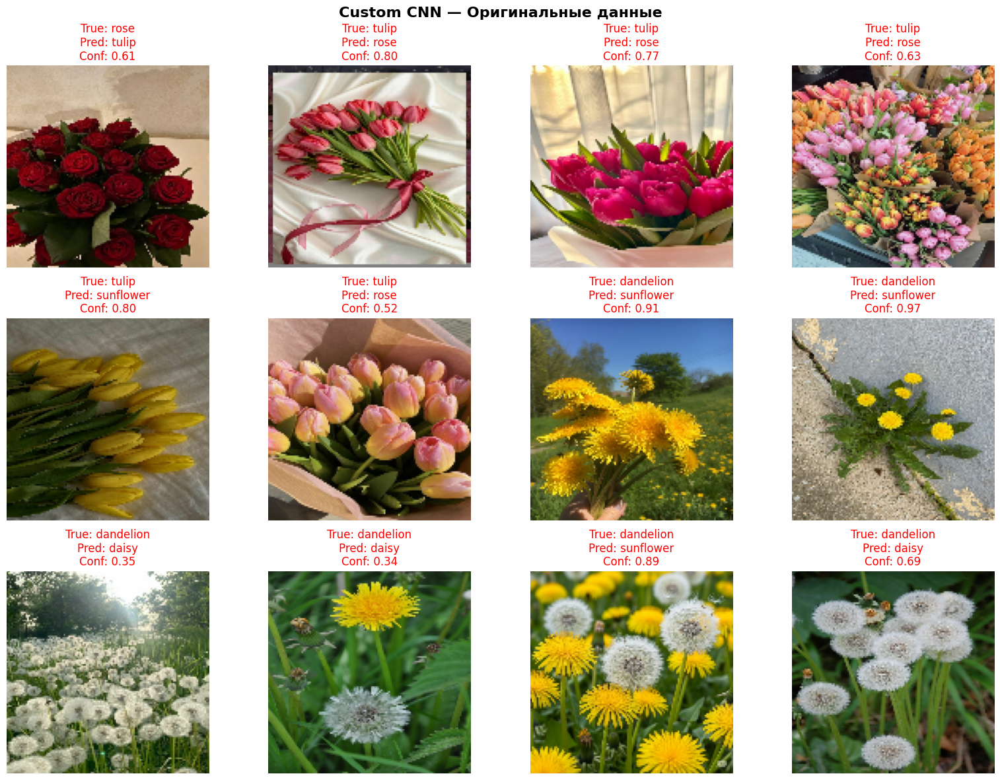


Custom CNN — Ручная аугментация
Всего изображений: 50 | Ошибок: 15 | Accuracy: 70.0%


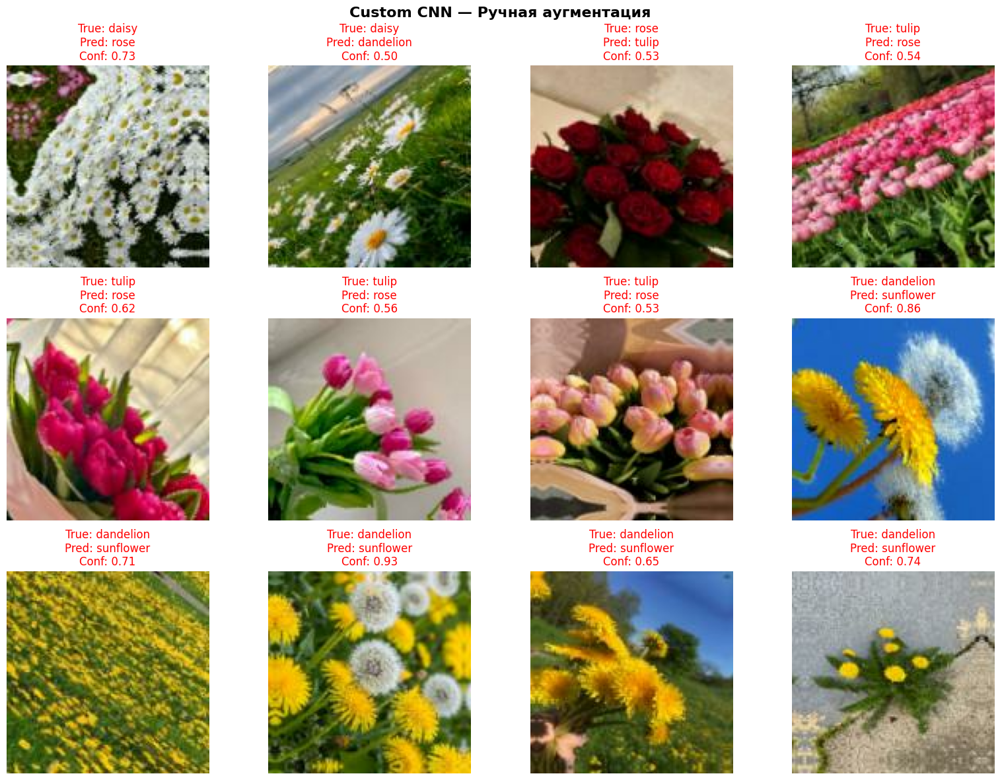


Custom CNN — AI-сгенерированные
Всего изображений: 50 | Ошибок: 11 | Accuracy: 78.0%


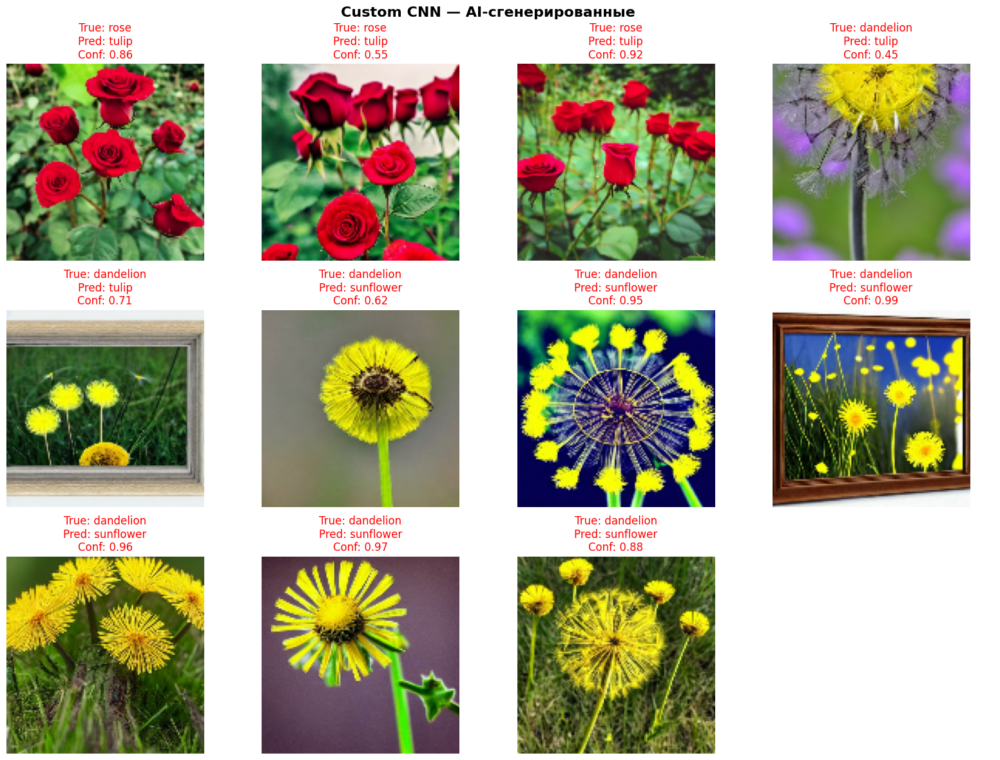

МОДЕЛЬ: MobileNetV2 (pretrained)

MobileNetV2 (pretrained) — Оригинальные данные
Всего изображений: 79 | Ошибок: 16 | Accuracy: 79.7%


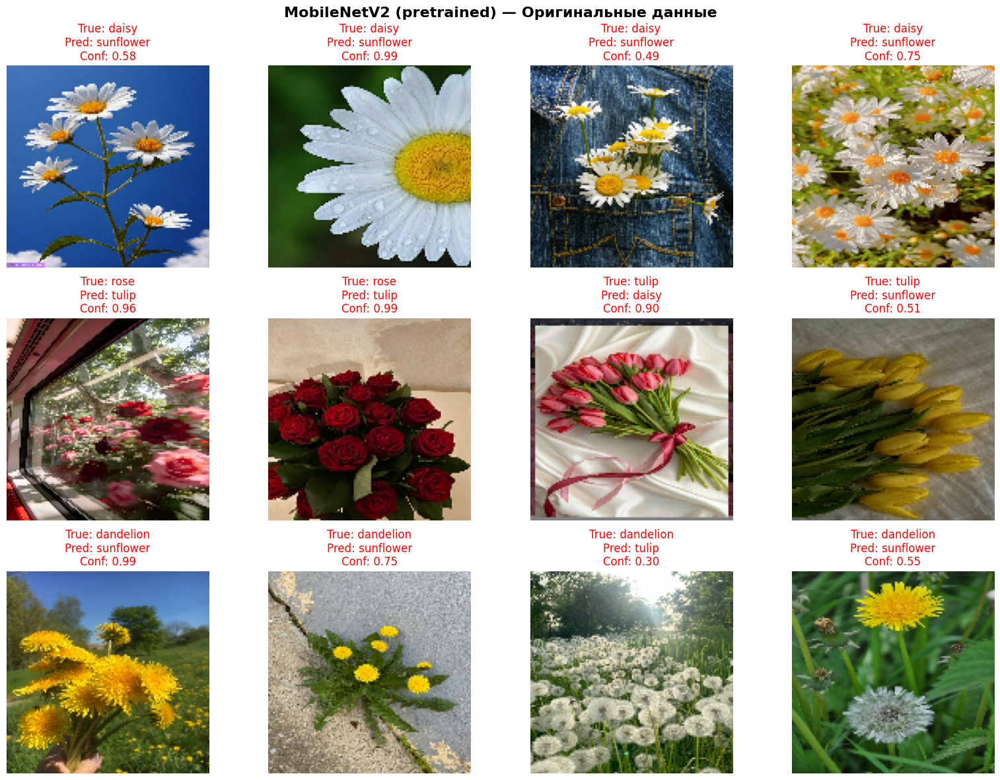


MobileNetV2 (pretrained) — Ручная аугментация
Всего изображений: 50 | Ошибок: 10 | Accuracy: 80.0%


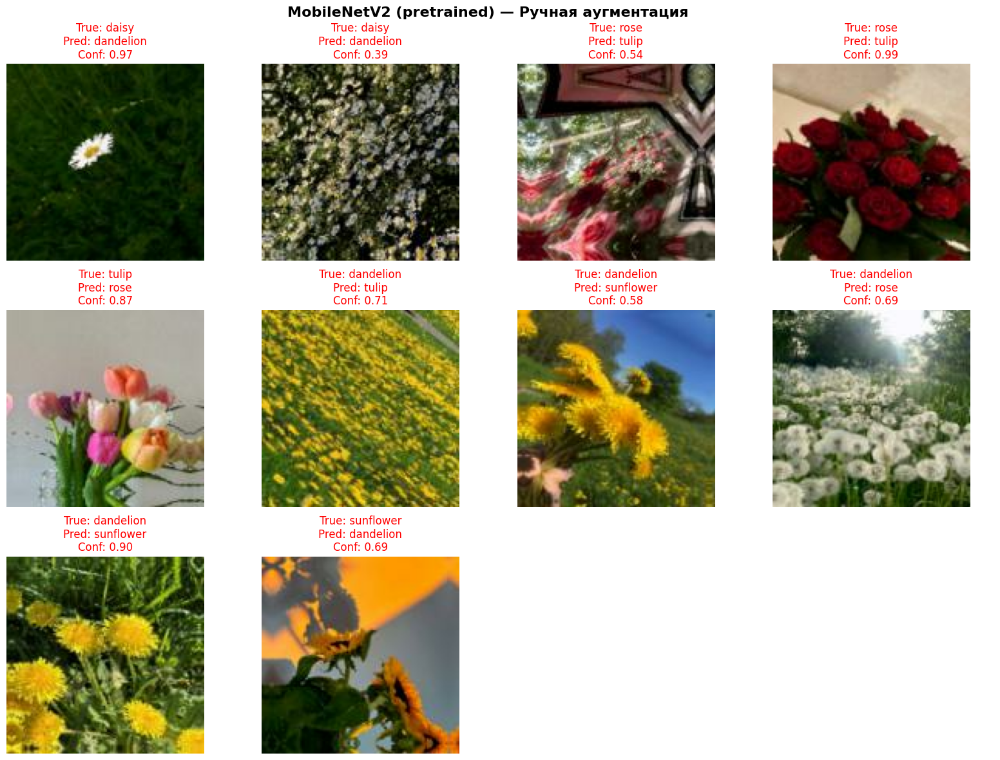


MobileNetV2 (pretrained) — AI-сгенерированные
Всего изображений: 50 | Ошибок: 6 | Accuracy: 88.0%


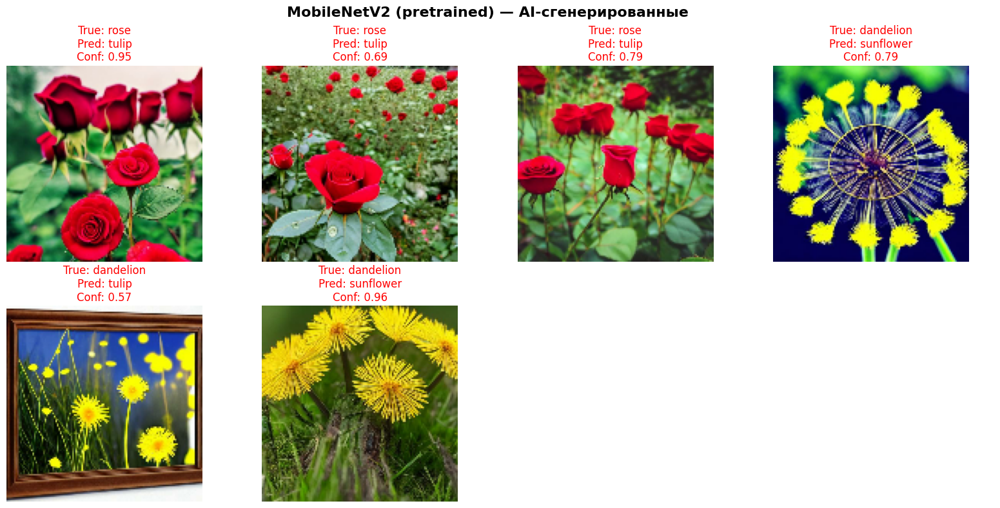

In [61]:
for model_name, model in models.items():
    print(f"МОДЕЛЬ: {model_name}")
    
    for dataset_name, path in folders.items():
        show_misclassifications(
            model=model,
            folder_path=path,
            class_names=classes,
            title=f"{model_name} — {dataset_name}"
        )

### На какие участки сеть «обращает внимание» 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
import os

Поиск последнего Conv2D

In [3]:
def find_last_conv_layer(model):

    # Если внутри есть pretrained model
    for layer in model.layers:

        if isinstance(layer, tf.keras.Model):

            conv_layers = [
                l for l in layer.layers
                if isinstance(l, tf.keras.layers.Conv2D)
            ]

            if len(conv_layers) > 0:
                return layer, conv_layers[-1].name

    # Обычный CNN
    conv_layers = [
        l for l in model.layers
        if isinstance(l, tf.keras.layers.Conv2D)
    ]

    return model, conv_layers[-1].name

In [ ]:
def find_last_conv_layer(model):

    # Если внутри есть pretrained model
    for layer in model.layers:

        if isinstance(layer, tf.keras.Model):

            conv_layers = [
                l for l in layer.layers
                if isinstance(l, tf.keras.layers.Conv2D)
            ]

            if len(conv_layers) > 0:
                return layer, conv_layers[-1].name

    # Обычный CNN
    conv_layers = [
        l for l in model.layers
        if isinstance(l, tf.keras.layers.Conv2D)
    ]

    return model, conv_layers[-1].name

In [4]:
def visualize_activations_simple(model, img_path, title=""):

    # Загружаем изображение

    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)

    img = tf.image.resize(img, (128, 128))

    img = tf.cast(img, tf.float32) / 255.0

    input_tensor = tf.expand_dims(img, axis=0)


    # Принудительно вызываем модель

    _ = model(input_tensor)

    # Ищем последний conv

    base_model, last_conv_name = find_last_conv_layer(model)

    print("Последний conv слой:", last_conv_name)

    # Создаём activation model 

    if base_model == model:

        # Custom CNN
        activation_model = tf.keras.Model(
            inputs=model.inputs,
            outputs=model.get_layer(last_conv_name).output
        )

        activations = activation_model(input_tensor)

    else:

        # MobileNetV2 внутри Sequential

        # Сначала прогоняем через слои ДО MobileNetV2
        x = input_tensor

        for layer in model.layers:

            if layer == base_model:
                break

            x = layer(x)

        # Создаём модель активаций для MobileNetV2
        activation_model = tf.keras.Model(
            inputs=base_model.inputs,
            outputs=base_model.get_layer(last_conv_name).output
        )

        activations = activation_model(x)

    # Обработка активаций
    activations = activations[0].numpy()

    heatmap = np.mean(activations, axis=-1)

    heatmap = np.maximum(heatmap, 0)

    heatmap /= (heatmap.max() + 1e-8)

    heatmap = cv2.resize(
        heatmap,
        (128, 128)
    )

    # Heatmap

    heatmap_colored = cv2.applyColorMap(
        np.uint8(255 * heatmap),
        cv2.COLORMAP_JET
    )

    original = np.uint8(img.numpy() * 255)

    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_colored,
        0.4,
        0
    )

    overlay = cv2.cvtColor(
        overlay,
        cv2.COLOR_BGR2RGB
    )

    # Визуализация

    plt.figure(figsize=(15, 5))

    plt.suptitle(
        f"{title}\n{os.path.basename(img_path)}",
        fontsize=14,
        fontweight="bold"
    )

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Оригинал")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap, cmap="jet")
    plt.title("Активации")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("Наложение")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [6]:
import pandas as pd

In [ ]:
df_example = collect_images("./flowers", classes) 
df_example = df_example.sample(5, random_state=42).reset_index(drop=True)

Изображение 1: sunflower
Последний conv слой: conv2d_2


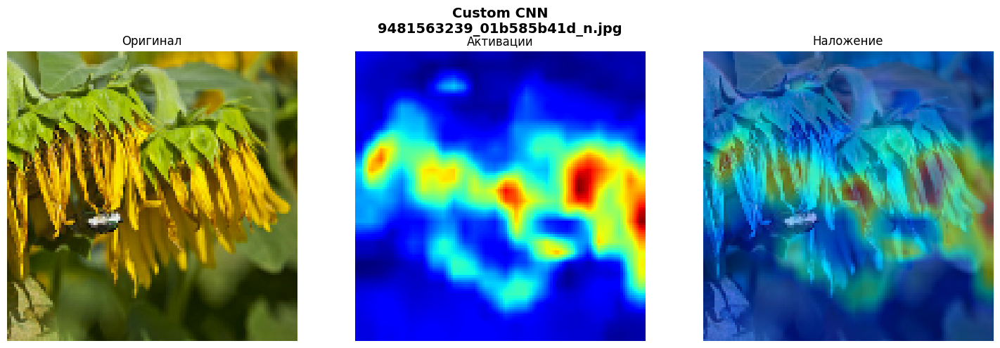

Последний conv слой: Conv_1


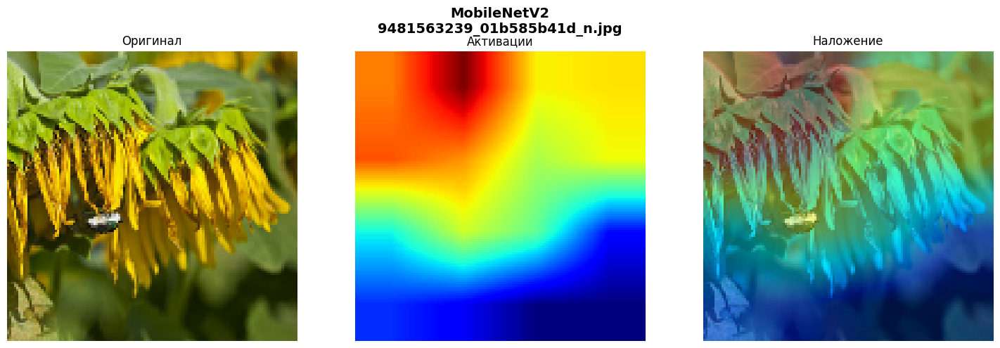

Изображение 2: tulip
Последний conv слой: conv2d_2


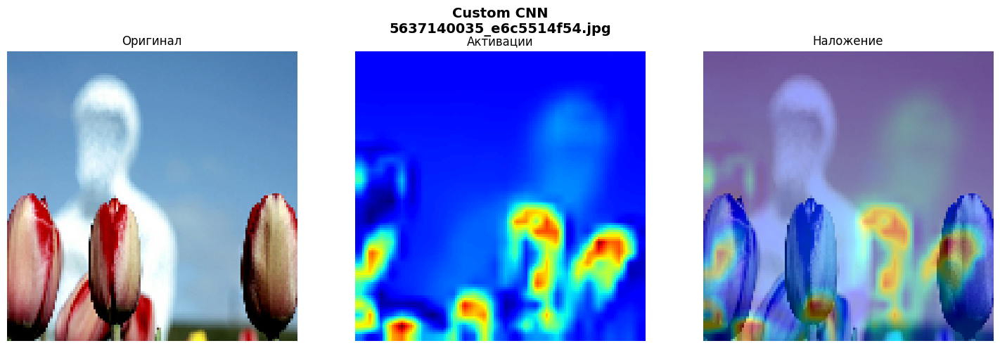

Последний conv слой: Conv_1


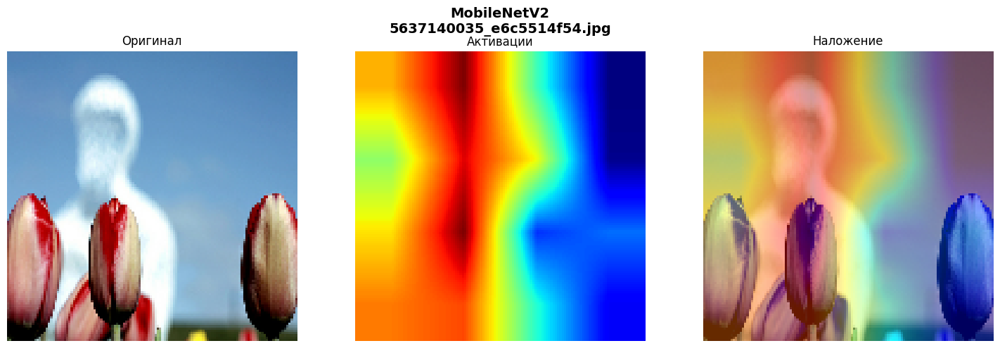

Изображение 3: tulip
Последний conv слой: conv2d_2


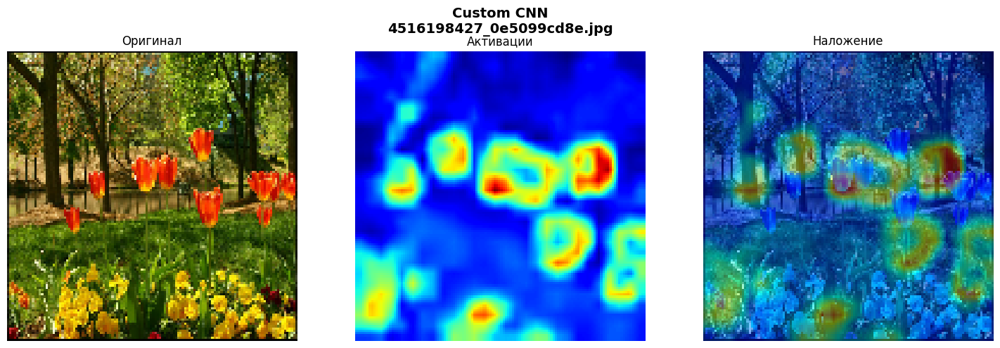

Последний conv слой: Conv_1


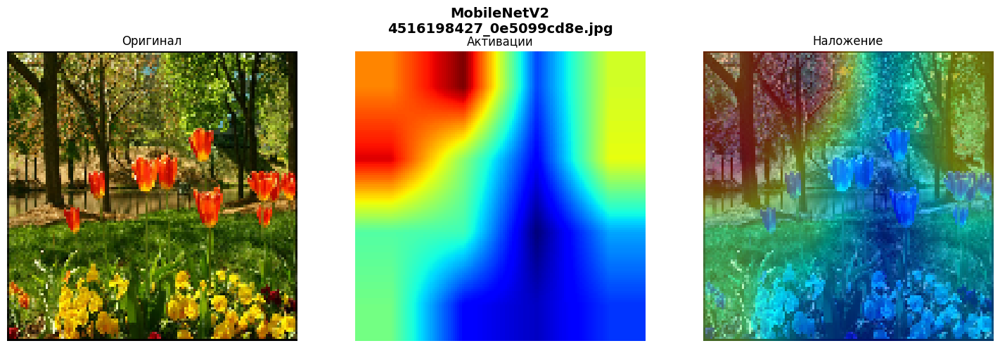

Изображение 4: dandelion
Последний conv слой: conv2d_2


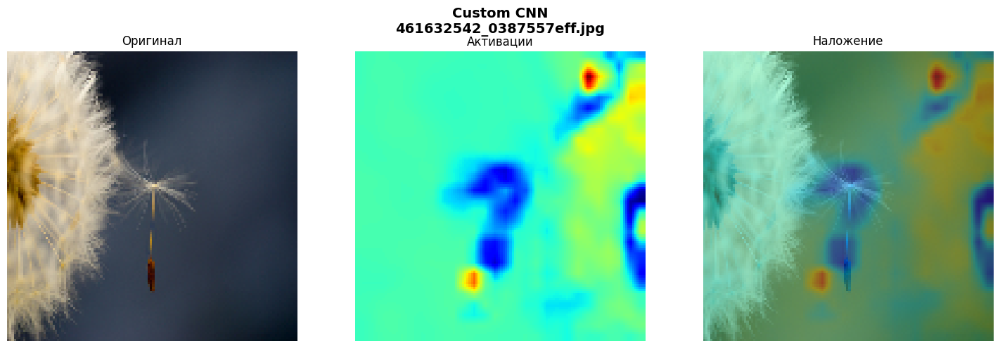

Последний conv слой: Conv_1


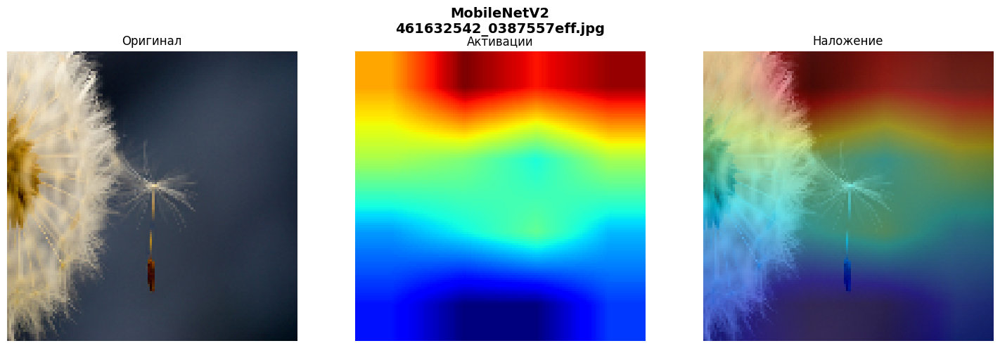

Изображение 5: sunflower
Последний conv слой: conv2d_2


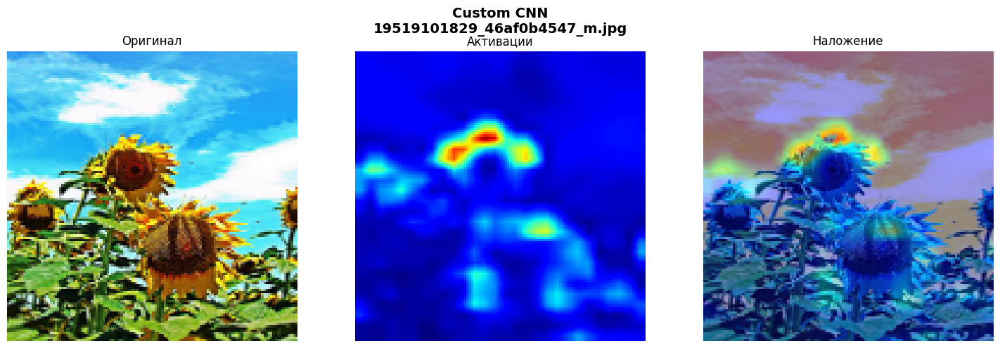

Последний conv слой: Conv_1


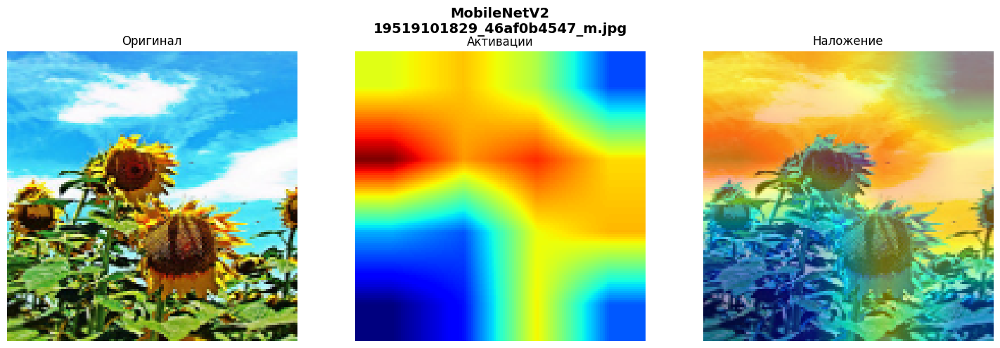

In [21]:
for i in range(min(5, len(df_example))):

    path = df_example.iloc[i]["filepath"]
    cls = df_example.iloc[i]["class_name"]

    print(f"Изображение {i+1}: {cls}")

    # Custom CNN
    visualize_activations_simple(
        cnn,
        path,
        "Custom CNN"
    )

    # MobileNetV2
    visualize_activations_simple(
        model_pretrained,
        path,
        "MobileNetV2"
    )

In [22]:
df_example = collect_images("./my_data", classes) 
df_example = df_example.sample(5, random_state=42).reset_index(drop=True)

Изображение 1: tulip
Последний conv слой: conv2d_2


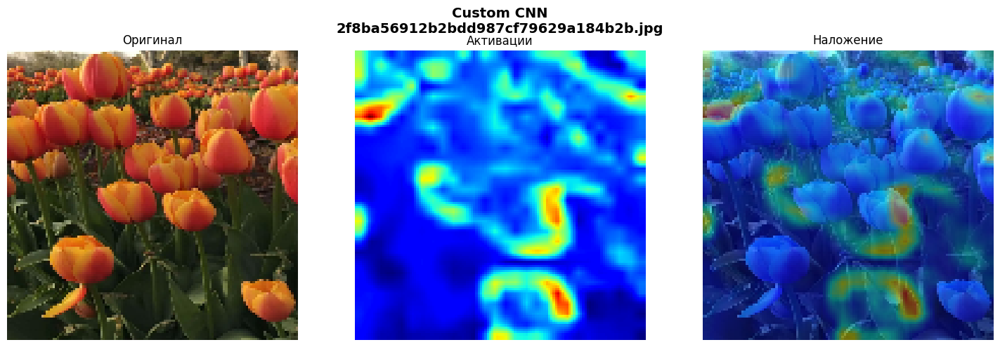

Последний conv слой: Conv_1


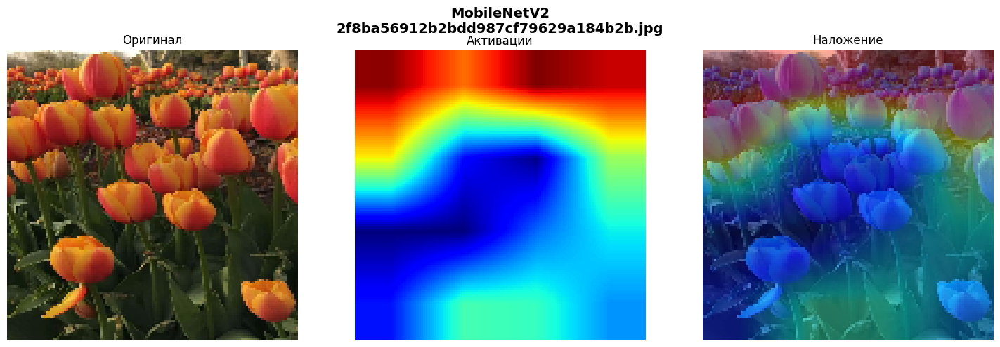

Изображение 2: daisy
Последний conv слой: conv2d_2


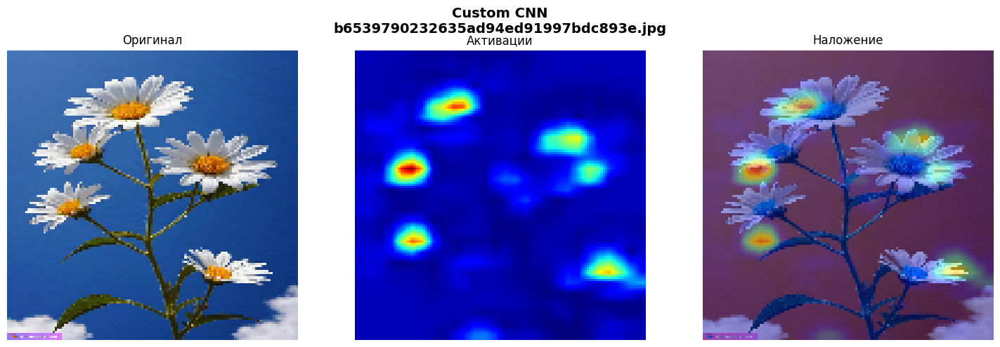

Последний conv слой: Conv_1


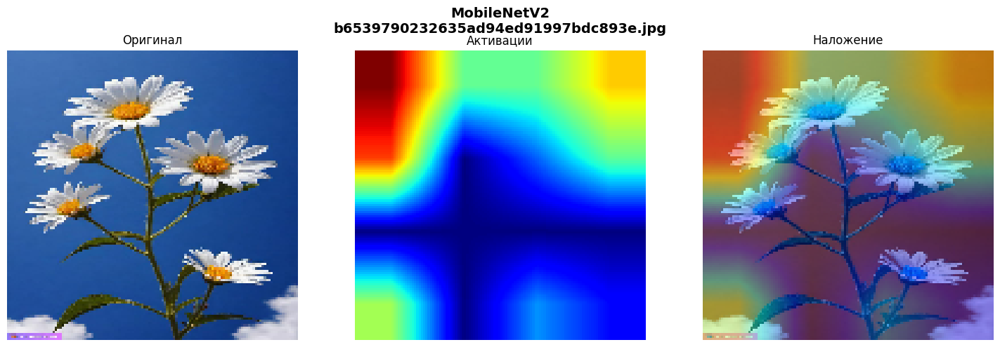

Изображение 3: rose
Последний conv слой: conv2d_2


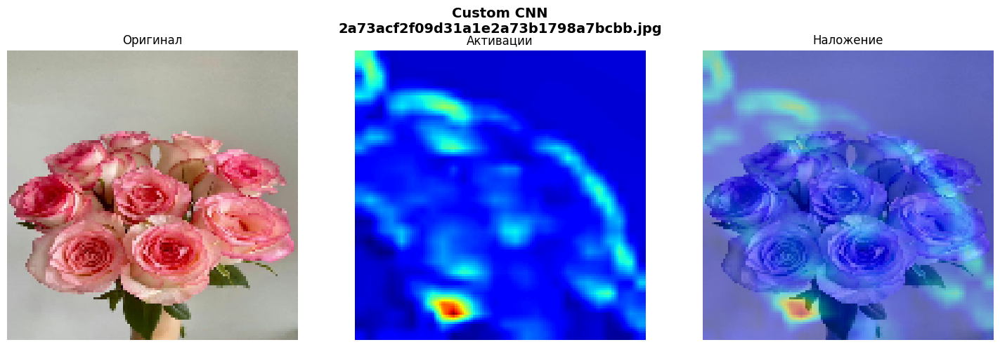

Последний conv слой: Conv_1


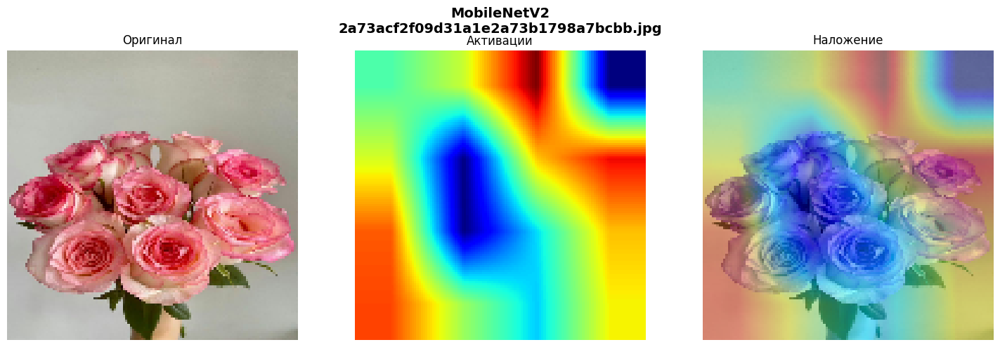

Изображение 4: tulip
Последний conv слой: conv2d_2


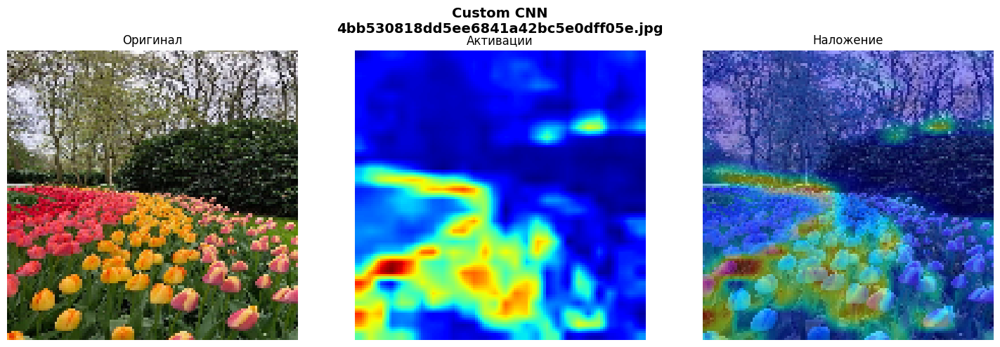

Последний conv слой: Conv_1


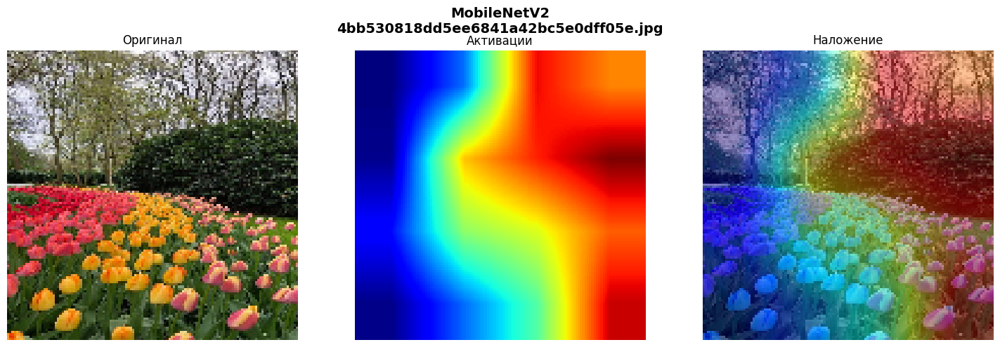

Изображение 5: rose
Последний conv слой: conv2d_2


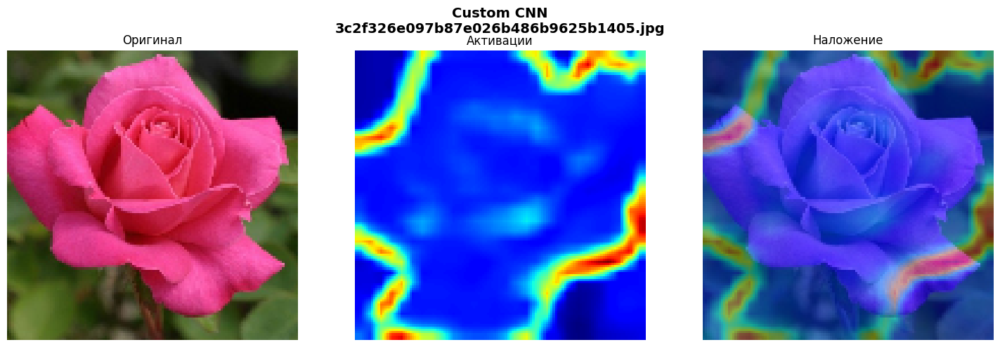

Последний conv слой: Conv_1


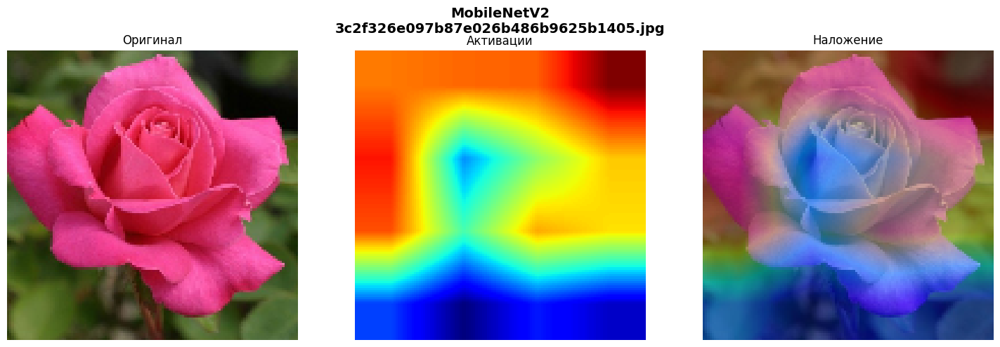

In [23]:
for i in range(min(5, len(df_example))):

    path = df_example.iloc[i]["filepath"]
    cls = df_example.iloc[i]["class_name"]

    print(f"Изображение {i+1}: {cls}")

    # Custom CNN
    visualize_activations_simple(
        cnn,
        path,
        "Custom CNN"
    )

    # MobileNetV2
    visualize_activations_simple(
        model_pretrained,
        path,
        "MobileNetV2"
    )

In [25]:
df_example = collect_images("./ai_generated", classes) 
df_example = df_example.sample(5, random_state=42).reset_index(drop=True)

Изображение 1: rose
Последний conv слой: conv2d_2


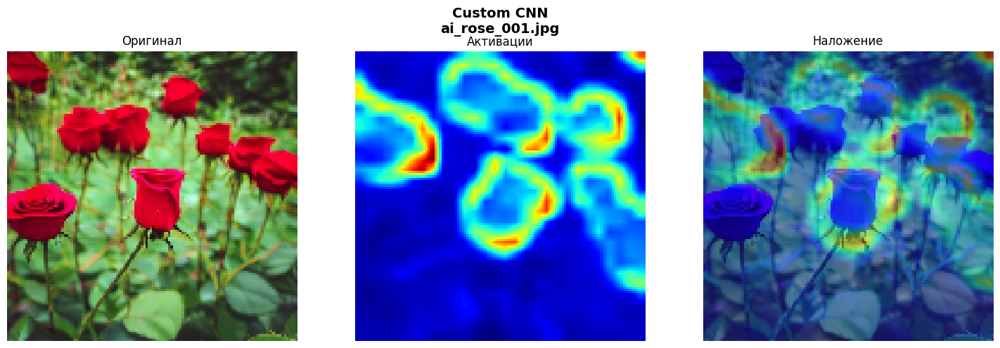

Последний conv слой: Conv_1


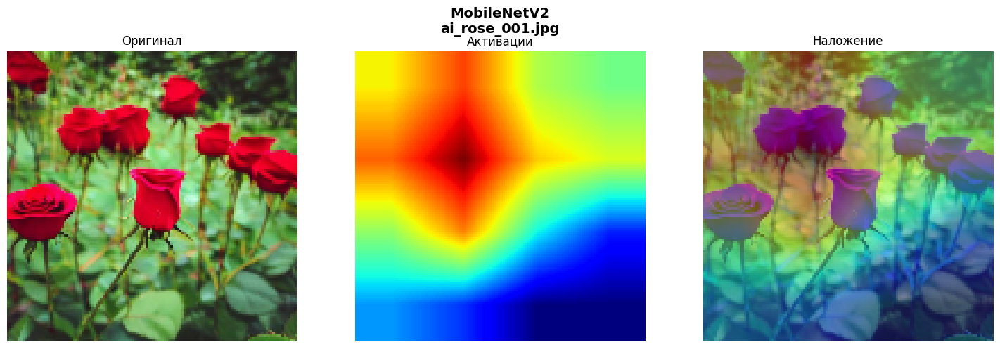

Изображение 2: dandelion
Последний conv слой: conv2d_2


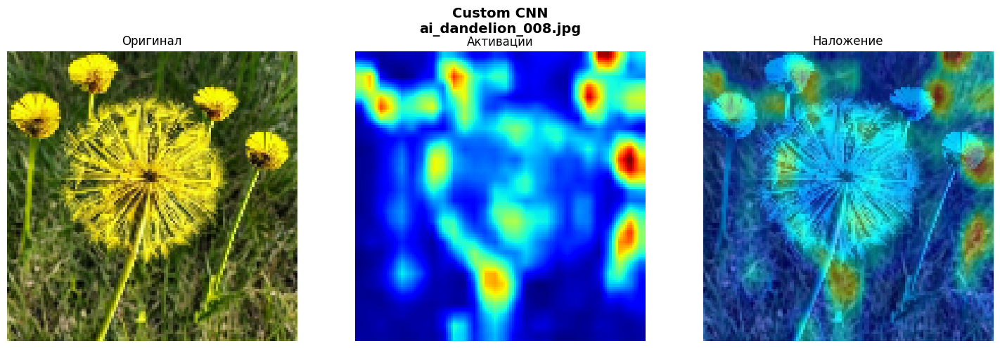

Последний conv слой: Conv_1


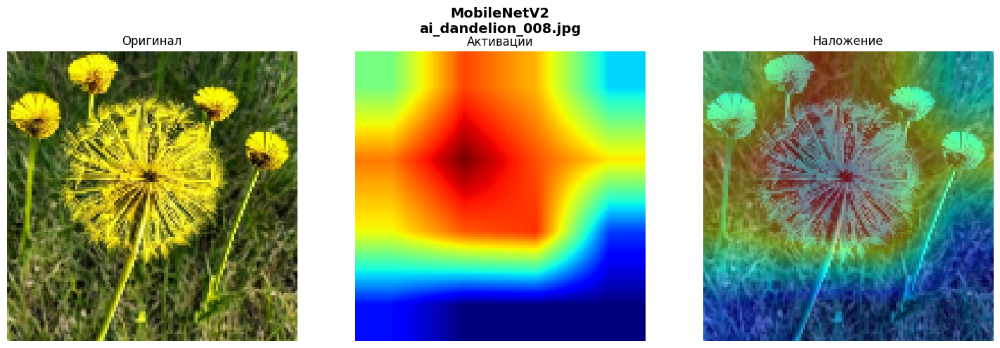

Изображение 3: dandelion
Последний conv слой: conv2d_2


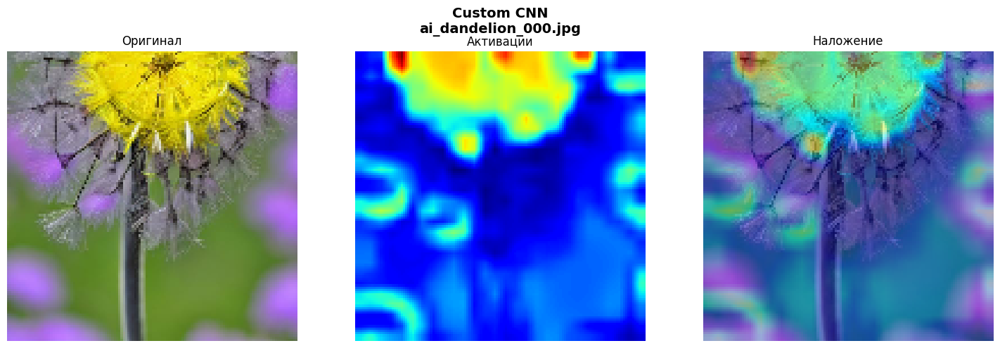

Последний conv слой: Conv_1


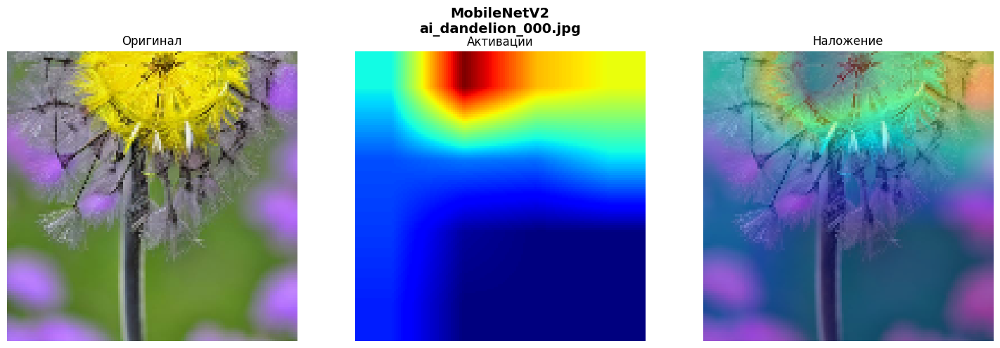

Изображение 4: sunflower
Последний conv слой: conv2d_2


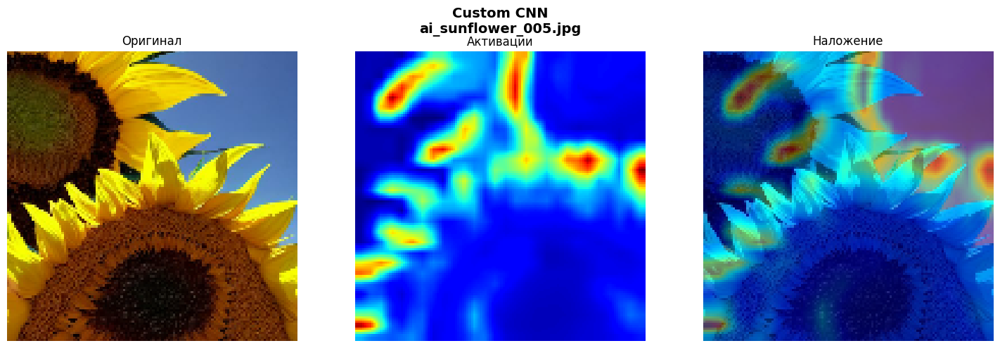

Последний conv слой: Conv_1


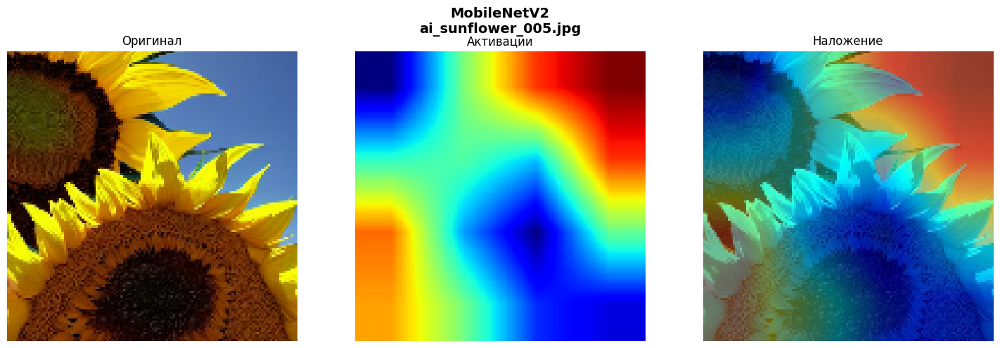

Изображение 5: rose
Последний conv слой: conv2d_2


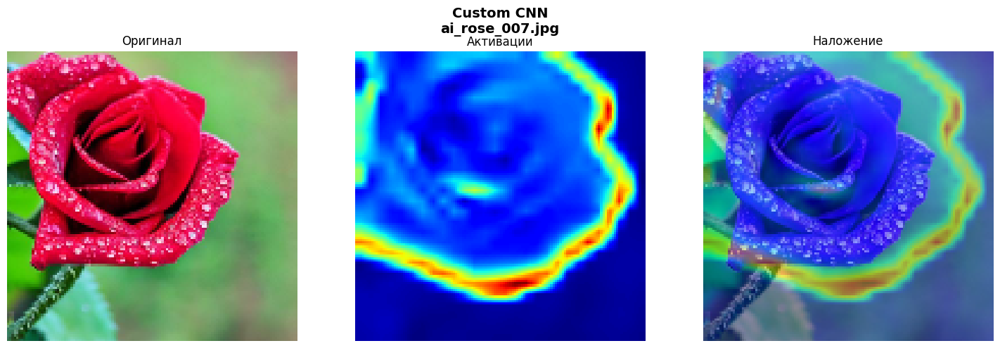

Последний conv слой: Conv_1


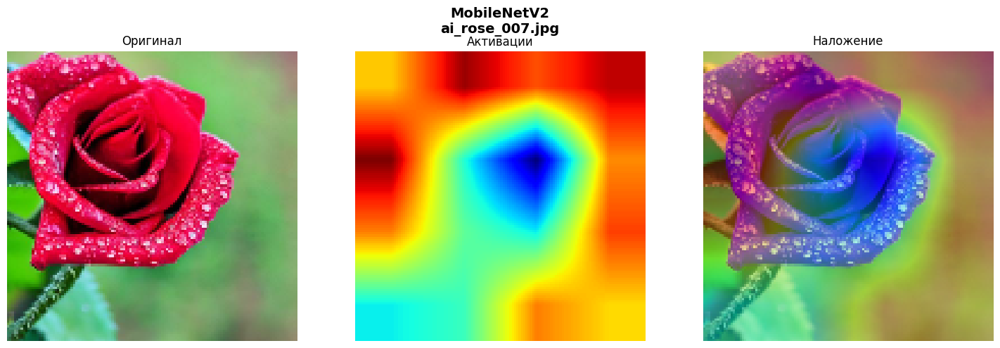

In [26]:
for i in range(min(5, len(df_example))):

    path = df_example.iloc[i]["filepath"]
    cls = df_example.iloc[i]["class_name"]

    print(f"Изображение {i+1}: {cls}")

    # Custom CNN
    visualize_activations_simple(
        cnn,
        path,
        "Custom CNN"
    )

    # MobileNetV2
    visualize_activations_simple(
        model_pretrained,
        path,
        "MobileNetV2"
    )